# Lending Game — Part 3: Fair pricing (break-even rates)

A loan of 1 euro at rate $r$ to a borrower with default probability $p$:

* with probability $1 - p$ the borrower repays and we earn $r$;
* with probability $p$ the borrower defaults and we lose the euro (recovery is zero).

Expected profit per euro lent:

$$\mathbb{E}[\pi] = (1 - p)\,r - p .$$

Setting it to zero gives the **break-even rate**

$$r^{*}(p) = \frac{p}{1 - p}.$$

At $r^*$ we expect to make exactly zero; any rate above it is profitable *if $p$ is right*.
$r^*$ is the **benchmark for every pricing decision**, a floor and not the price we will charge
(Part 6 decides the price). Two rules apply everywhere:

* **No offer when $p \ge 0.5$**: then $r^* \ge 100\%$, and the game forbids rates above 100%.
* "No offer" is a missing rate (`NaN`), as in the submission file and the simulator.

This notebook applies the Part 3 functions (`src/fair_pricing.py`) to the Part 2 predictions
(`data/predictions/`), checks that break-even pricing does break even, shows why it is only a floor
under competition, and builds the competitor offers used in Parts 6 and 7.

## 0. Setup

In [1]:
import sys
sys.path.append("..")  # make src/ importable from analysis/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import DATA_PREDICTIONS, LOAN_AMOUNT
from src.fair_pricing import (NO_OFFER_THRESHOLD, offer, break_even_rate, add_offer_flags,
                              add_break_even_rates, competitor_offers)
from src import model_plots as mp

mp.set_style()
pd.set_option("display.width", 160)

INFO_SETS = ["own", "full", "lender1", "lender2", "public"]
P_COLS = [f"p_{i}" for i in INFO_SETS]

# Part 2 predictions of the selected models (spline logistic for every information set).
val = pd.read_csv(DATA_PREDICTIONS / "validation_selected.csv", index_col="row_id")
train = pd.read_csv(DATA_PREDICTIONS / "train_oof_selected.csv", index_col="row_id")
apps = pd.read_csv(DATA_PREDICTIONS / "applications_own.csv", index_col="id")

print(f"validation   : {len(val):>7,} loans, models fitted on train only")
print(f"train (OOF)  : {len(train):>7,} loans, out-of-fold predictions")
print(f"applications : {len(apps):>7,} new applicants, p_own only")
val.head()

validation   :  20,000 loans, models fitted on train only
train (OOF)  :  80,000 loans, out-of-fold predictions
applications : 100,000 new applicants, p_own only


,default,p_own,p_full,p_lender1,p_lender2,p_public
row_id,,,,,,
77965,0,0.134570,0.151730,0.127125,0.264413,0.174594
75716,0,0.061535,0.030150,0.048614,0.040710,0.064046
49786,0,0.036106,0.021656,0.041708,0.035977,0.051587
10820,0,0.102367,0.109800,0.126432,0.129494,0.124682
81056,0,0.001735,0.002260,0.002640,0.002085,0.002044


## 1. The break-even curve

Left: the break-even rate as a function of $p$. Right: where our predicted probabilities actually
lie (validation set), which tells us which part of the curve matters in practice.

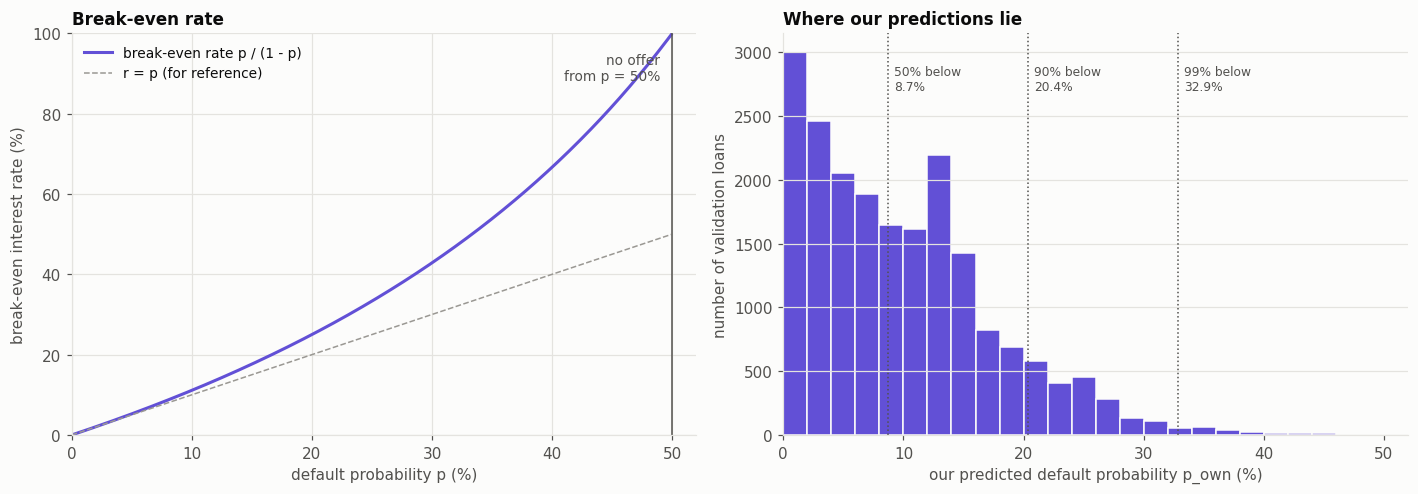

,p,break-even rate,offer
0,1%,1.01%,1
1,5%,5.26%,1
2,10%,11.11%,1
3,20%,25.00%,1
4,30%,42.86%,1
5,40%,66.67%,1
6,45%,81.82%,1
7,49%,96.08%,1
8,50%,no offer,0


In [2]:
p_grid = np.linspace(0, 0.499, 500)
r_grid = break_even_rate(p_grid)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.plot(100 * p_grid, 100 * r_grid, color=mp.SINGLE_COLOR, label="break-even rate p / (1 - p)")
ax.plot(100 * p_grid, 100 * p_grid, color=mp.REFERENCE, lw=1, ls="--", label="r = p (for reference)")
ax.axvline(100 * NO_OFFER_THRESHOLD, color=mp.INK_SECONDARY, lw=1)
ax.text(100 * NO_OFFER_THRESHOLD - 1, 95, "no offer\nfrom p = 50%", ha="right", va="top",
        fontsize=9, color=mp.INK_SECONDARY)
ax.set_xlim(0, 52); ax.set_ylim(0, 100)
ax.set_xlabel("default probability p (%)")
ax.set_ylabel("break-even interest rate (%)")
ax.set_title("Break-even rate")
ax.legend(loc="upper left")

ax = axes[1]
ax.hist(100 * val["p_own"], bins=np.arange(0, 52, 2), color=mp.SINGLE_COLOR,
        edgecolor=mp.SURFACE, linewidth=1)
for q in [0.5, 0.9, 0.99]:
    x = 100 * val["p_own"].quantile(q)
    ax.axvline(x, color=mp.INK_SECONDARY, lw=1, ls=":")
    ax.text(x + 0.5, ax.get_ylim()[1] * 0.92, f"{q:.0%} below\n{x:.1f}%", fontsize=8,
            color=mp.INK_SECONDARY, va="top")
ax.set_xlim(0, 52)
ax.grid(axis="x", visible=False)
ax.set_xlabel("our predicted default probability p_own (%)")
ax.set_ylabel("number of validation loans")
ax.set_title("Where our predictions lie")
fig.tight_layout()
plt.show()

examples = pd.DataFrame({"p": [0.01, 0.05, 0.10, 0.20, 0.30, 0.40, 0.45, 0.49, 0.50]})
examples["break-even rate"] = break_even_rate(examples["p"])
examples["offer"] = offer(examples["p"])
display(examples.style.format({"p": "{:.0%}", "break-even rate": "{:.2%}"}, na_rep="no offer"))

**Reading the curve.**

* For low-risk borrowers the break-even rate is almost equal to $p$: 1.01% at $p = 1\%$, 5.26% at
  $p = 5\%$. Half of our validation borrowers have $p$ below 8.7%, so for most of the market the
  break-even rate is a few points at most.
* The curve is **convex**: the rate grows faster than $p$ (25% at $p = 20\%$, 42.9% at 30%, 66.7% at
  40%) and tends to 100% as $p \to 50\%$. Its slope is $1/(1-p)^2$: an error of 1 point in $p$ moves
  the rate by about 1 point for a safe borrower but by about 2 points at $p = 30\%$. Mistakes in $p$
  cost more for risky borrowers.
* The cut-off at $p = 50\%$ barely matters in practice: 99% of our predictions are below 32.9%, where
  the break-even rate is under 50%.

## 2. Break-even rates for all Part 2 predictions

`add_break_even_rates` adds one rate column per probability column (`be_p_own`, ...) and
`add_offer_flags` one 0/1 offer flag (`offer_p_own`, ...). Applied to the selected models' predictions
for the five information sets, on the validation set and on the out-of-fold training predictions.

In [3]:
val_be = add_offer_flags(add_break_even_rates(val, P_COLS), P_COLS)
train_be = add_offer_flags(add_break_even_rates(train, P_COLS), P_COLS)


def rate_summary(frame):
    # Distribution of the break-even rates of each information set.
    rows = {}
    for i in INFO_SETS:
        r = frame[f"be_p_{i}"]
        rows[i] = {"mean": r.mean(), "median": r.median(), "10%": r.quantile(0.10),
                   "90%": r.quantile(0.90), "99%": r.quantile(0.99), "max": r.max(),
                   "no offer": int((frame[f"offer_p_{i}"] == 0).sum())}
    return pd.DataFrame(rows).T


fmt = {c: "{:.2%}" for c in ["mean", "median", "10%", "90%", "99%", "max"]} | {"no offer": "{:,.0f}"}
print("Break-even rates, validation set")
display(rate_summary(val_be).style.format(fmt))
print("Break-even rates, training set (out of fold)")
display(rate_summary(train_be).style.format(fmt))

Break-even rates, validation set


,mean,median,10%,90%,99%,max,no offer
own,11.97%,9.54%,1.27%,25.56%,48.93%,86.81%,0
full,12.05%,8.56%,1.10%,27.25%,62.15%,99.17%,52
lender1,11.98%,9.62%,1.29%,25.27%,49.37%,79.57%,0
lender2,11.90%,9.65%,1.27%,25.66%,47.25%,78.80%,0
public,11.77%,10.21%,1.37%,21.15%,34.80%,40.96%,0


Break-even rates, training set (out of fold)


,mean,median,10%,90%,99%,max,no offer
own,11.97%,9.52%,1.24%,25.87%,50.06%,97.68%,0
full,12.10%,8.46%,1.07%,27.62%,62.94%,99.87%,207
lender1,11.97%,9.49%,1.25%,25.88%,49.94%,89.56%,0
lender2,11.94%,9.53%,1.26%,26.15%,47.28%,80.81%,0
public,11.75%,10.13%,1.35%,21.48%,35.02%,47.22%,0


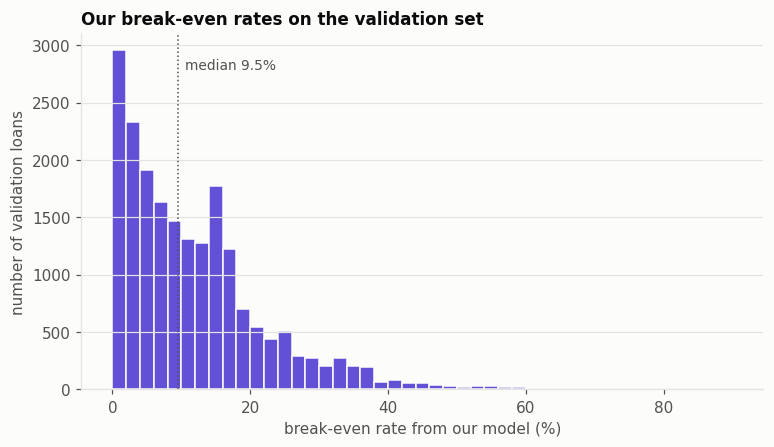

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(100 * val_be["be_p_own"], bins=np.arange(0, 92, 2), color=mp.SINGLE_COLOR,
        edgecolor=mp.SURFACE, linewidth=1)
ax.axvline(100 * val_be["be_p_own"].median(), color=mp.INK_SECONDARY, lw=1, ls=":")
ax.text(100 * val_be["be_p_own"].median() + 1, ax.get_ylim()[1] * 0.9,
        f"median {val_be['be_p_own'].median():.1%}", fontsize=9, color=mp.INK_SECONDARY)
ax.grid(axis="x", visible=False)
ax.set_xlabel("break-even rate from our model (%)")
ax.set_ylabel("number of validation loans")
ax.set_title("Our break-even rates on the validation set")
plt.show()

**What the break-even rates look like.**

* With our model, the median break-even rate is **9.5%** and the mean **12.0%**. The mean is higher
  than the mean default probability (10%) because the curve is convex. 80% of borrowers fall between
  1.3% and 25.6%, and the highest rate on validation is 86.8%.
* **No validation borrower gets "no offer"** from our model (none has $p \ge 0.5$). Only the
  full-information model, which separates risk more sharply, produces such borrowers (52 on
  validation, 207 in training). The public-only model is the most compressed (maximum 41%): with less
  information, predictions stay closer to the average.
* Lender 1's and lender 2's break-even rates have almost the same distribution as ours. Their
  models are as good as ours; they differ on *which* borrowers are risky, not on the overall level.
* Training (out-of-fold) and validation distributions agree.

## 3. Does break-even pricing break even?

Without competition, suppose we lent to **every** validation applicant at our break-even rate.
On each loan the realized profit per euro is $r^*$ if the borrower repays and $-1$ if they default.
If our probabilities are right, the average realized profit should be close to zero, overall and at
every risk level. This links Part 2's calibration directly to pricing.

,loans,avg rate,profit per euro,total profit (EUR)
Own (signal 3),"20,000",11.97%,+0.0002,"+35,563"
Full (signals 1-3),"19,948",12.05%,-0.0004,"-86,472"
Lender 1 (signal 1),"20,000",11.98%,+0.0002,"+32,588"
Lender 2 (signal 2),"20,000",11.90%,-0.0002,"-40,981"
Public only,"20,000",11.77%,+0.0004,"+77,079"


,mean_p,observed_default,mean_rate,profit_per_euro,loans,ci95
decile,,,,,,
D1,0.58%,0.65%,0.58%,-0.0008,2000,±0.0035
D2,2.00%,2.50%,2.04%,-0.0051,2000,±0.0070
D3,3.60%,3.45%,3.74%,+0.0016,2000,±0.0083
D4,5.47%,5.00%,5.79%,+0.0050,2000,±0.0101
D5,7.58%,7.75%,8.21%,-0.0018,2000,±0.0127
D6,9.95%,9.25%,11.05%,+0.0078,2000,±0.0141
D7,12.35%,12.10%,14.09%,+0.0029,2000,±0.0163
D8,14.22%,14.45%,16.58%,-0.0028,2000,±0.0180
D9,17.80%,17.90%,21.70%,-0.0011,2000,±0.0205


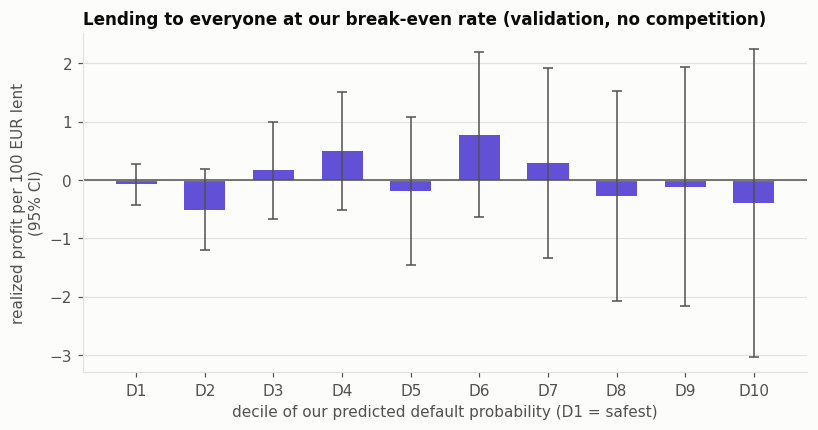

In [5]:
def realized_profit_per_euro(rate, default):
    # Profit per euro lent on each loan: +rate if repaid, -1 if defaulted (NaN rate = no loan).
    return np.where(default == 1, -1.0, rate)


rows = {}
for i in INFO_SETS:
    lent = val_be[f"offer_p_{i}"] == 1
    profit = realized_profit_per_euro(val_be.loc[lent, f"be_p_{i}"], val_be.loc[lent, "default"])
    rows[mp.INFO_SET_LABELS[i]] = {"loans": int(lent.sum()),
                                   "avg rate": val_be.loc[lent, f"be_p_{i}"].mean(),
                                   "profit per euro": profit.mean(),
                                   "total profit (EUR)": profit.sum() * LOAN_AMOUNT}
display(pd.DataFrame(rows).T.style.format({"loans": "{:,.0f}", "avg rate": "{:.2%}",
                                           "profit per euro": "{:+.4f}",
                                           "total profit (EUR)": "{:+,.0f}"}))

# By decile of our predicted risk
deciles = pd.qcut(val_be["p_own"], 10, labels=[f"D{k}" for k in range(1, 11)])
by_decile = (pd.DataFrame({"decile": deciles, "p": val_be["p_own"], "rate": val_be["be_p_own"],
                           "default": val_be["default"],
                           "profit": realized_profit_per_euro(val_be["be_p_own"], val_be["default"])})
             .groupby("decile", observed=True)
             .agg(mean_p=("p", "mean"), observed_default=("default", "mean"),
                  mean_rate=("rate", "mean"), profit_per_euro=("profit", "mean"),
                  profit_sd=("profit", "std"), loans=("profit", "size")))
# 95% confidence interval of the mean profit: sampling noise of 2,000 loans per decile
by_decile["ci95"] = 1.96 * by_decile["profit_sd"] / np.sqrt(by_decile["loans"])
display(by_decile.drop(columns="profit_sd")
        .style.format({"mean_p": "{:.2%}", "observed_default": "{:.2%}", "mean_rate": "{:.2%}",
                       "profit_per_euro": "{:+.4f}", "ci95": "±{:.4f}"}))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(by_decile.index.astype(str), 100 * by_decile["profit_per_euro"], color=mp.SINGLE_COLOR, width=0.6,
       yerr=100 * by_decile["ci95"], error_kw={"ecolor": mp.INK_SECONDARY, "elinewidth": 1, "capsize": 3})
ax.axhline(0, color=mp.INK_SECONDARY, lw=1)
ax.grid(axis="x", visible=False)
ax.set_xlabel("decile of our predicted default probability (D1 = safest)")
ax.set_ylabel("realized profit per 100 EUR lent\n(95% CI)")
ax.set_title("Lending to everyone at our break-even rate (validation, no competition)")
plt.show()

**Yes: without competition, break-even pricing breaks even.**

* Lending to all 20,000 validation borrowers at our break-even rate yields **+0.0002 per euro**, i.e.
  +EUR 36k on EUR 200M lent, which is essentially zero. All five information sets are within ±0.0004
  per euro.
* By decile of predicted risk, realized profit is never further from zero than 0.8 euro per 100
  lent, and every decile is **within its 95% confidence interval** (the error bars). The pattern is
  noise, not bias: our probabilities are right at every risk level, which is the condition for the
  break-even rate to mean what it says.

This is the monopoly case: we lend to everyone, so nothing selects which borrowers we get.

## 4. Why break-even is only a floor: competition

Now add the two competitors. In the simplest scenario, every lender offers its own break-even rate
(lenders 1 and 2 with our reconstruction of their models) and each borrower takes the cheapest offer.
Borrower preferences (the 2-point discount for a preferred lender) are ignored here; the Part 4
simulator includes them.

In [6]:
offers = pd.DataFrame({"lender 1": val_be["be_p_lender1"], "lender 2": val_be["be_p_lender2"],
                       "us (lender 3)": val_be["be_p_own"]})
winner = offers.idxmin(axis=1)  # cheapest offer wins (no offer = NaN never wins)
won = winner == "us (lender 3)"

profit = realized_profit_per_euro(val_be.loc[won, "be_p_own"], val_be.loc[won, "default"])
competition = pd.Series({
    "loans we win": int(won.sum()),
    "share of applicants": won.mean(),
    "our average predicted p": val_be.loc[won, "p_own"].mean(),
    "observed default rate": val_be.loc[won, "default"].mean(),
    "our average rate": val_be.loc[won, "be_p_own"].mean(),
    "profit per euro lent": profit.mean(),
    "total profit (EUR)": profit.sum() * LOAN_AMOUNT,
})
formats = {"loans we win": "{:,.0f}", "share of applicants": "{:.1%}", "our average predicted p": "{:.2%}",
           "observed default rate": "{:.2%}", "our average rate": "{:.2%}",
           "profit per euro lent": "{:+.4f}", "total profit (EUR)": "{:+,.0f}"}
display(competition.to_frame("everyone prices at break-even")
        .apply(lambda col: [formats[k].format(v) for k, v in col.items()]))

,everyone prices at break-even
loans we win,"6,657"
share of applicants,33.3%
our average predicted p,8.00%
observed default rate,10.06%
our average rate,9.18%
profit per euro lent,-0.0243
total profit (EUR),"-1,615,073"


**With competition, the same rates lose money.** We are the cheapest lender for one third of
applicants (6,657 loans). For them we predicted an average default rate of **8.0%**, but **10.1%**
defaulted. At an average rate of 9.2%, that is a loss of **2.4 cents per euro lent**, about
**EUR -1.6 million** on these loans.

This is the winner's curse. Our predictions are right on average, but a borrower who
picks us because our rate is the lowest is disproportionately one whose risk we under-estimated. The
break-even rate assumes the borrower is a random draw at that $p$; under competition they are not.
Hence **break-even is a floor**: the price we charge must add a margin that covers this adverse
selection. Part 5 measures it with the full simulator (including preferences), and Part 6 designs
the rule.

## 5. Competitor offers

`competitor_offers(p_comp, margin)` models a competitor's rate as its break-even rate plus an
assumed margin. The margin is unknown: it is the scenario parameter of Parts 6 and 7. No offer
when $p \ge 0.5$ or when the rate would exceed 100%; a negative margin (a competitor pricing below
its break-even) is allowed, but the rate never goes below 0%.

The table shows lender 1's offers for a range of margins. The chart shows, for each margin, the
share of validation applicants for whom our break-even rate is below **both** competitors' offers:
how much of the market we could win while still covering our expected losses.

,median offer,mean offer,offers at 0%,no offer
lender 1 margin,,,,
-2%,7.62%,10.14%,"2,970",0
+0%,9.62%,11.98%,0,0
+1%,10.62%,12.98%,0,0
+2%,11.62%,13.98%,0,0
+3%,12.62%,14.98%,0,0
+5%,14.62%,16.98%,0,0
+10%,19.62%,21.98%,0,0


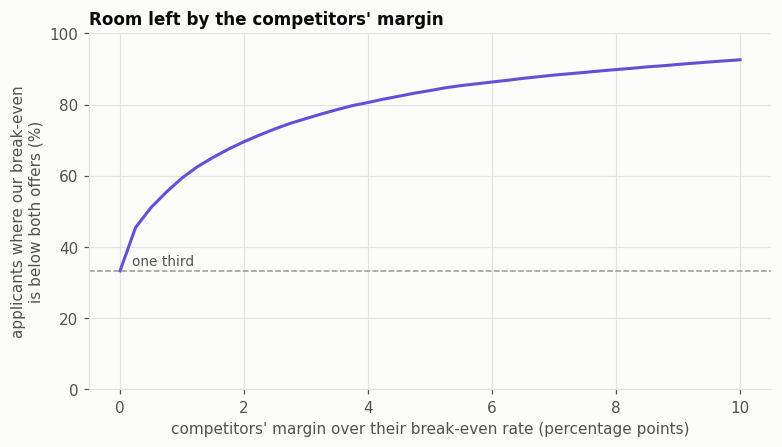

In [7]:
margins = [-0.02, 0.0, 0.01, 0.02, 0.03, 0.05, 0.10]
rows = {}
for m in margins:
    r1 = competitor_offers(val_be["p_lender1"], m)
    rows[f"{m:+.0%}"] = {"median offer": r1.median(), "mean offer": r1.mean(),
                         "offers at 0%": int((r1 == 0).sum()), "no offer": int(r1.isna().sum())}
display(pd.DataFrame(rows).T.rename_axis("lender 1 margin")
        .style.format({"median offer": "{:.2%}", "mean offer": "{:.2%}",
                       "offers at 0%": "{:,.0f}", "no offer": "{:,.0f}"}))

margin_grid = np.linspace(0, 0.10, 41)
share_below = [((val_be["be_p_own"] < competitor_offers(val_be["p_lender1"], m).fillna(np.inf))
                & (val_be["be_p_own"] < competitor_offers(val_be["p_lender2"], m).fillna(np.inf))).mean()
               for m in margin_grid]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(100 * margin_grid, 100 * np.array(share_below), color=mp.SINGLE_COLOR)
ax.axhline(100 / 3, color=mp.REFERENCE, lw=1, ls="--")
ax.text(0.2, 100 / 3 + 1.5, "one third", fontsize=9, color=mp.INK_SECONDARY)
ax.set_ylim(0, 100)
ax.set_xlabel("competitors' margin over their break-even rate (percentage points)")
ax.set_ylabel("applicants where our break-even\nis below both offers (%)")
ax.set_title("Room left by the competitors' margin")
plt.show()

**How the competitors' margin changes the game.**

* `competitor_offers` shifts every break-even rate by the margin. With a **-2% margin** (a competitor
  pricing below cost), 2,970 offers are floored at 0% rather than becoming negative.
* If both competitors price at their break-even rate (margin 0), our break-even rate is below both
  offers for **33%** of applicants, which is the symmetric split. Each point of margin they add opens
  room for us: 59% at +1 point, 70% at +2, 84% at +5, 93% at +10.
* These are the applicants we *could* win without pricing below our expected cost, before preferences
  and before correcting for the winner's curse. A larger competitor margin leaves us more room to add
  our own margin and still win. The margin is unknown, so Parts 6 and 7 test a range of values.

## 6. Break-even rates for the new applications

Our model's predictions for the 100,000 new applicants (Part 2, `applications_own.csv`), turned into
break-even rates and offer flags. Their distribution should match the validation set's, since the
applicants come from the same population.

,applications,validation
mean,11.98%,11.97%
std,10.89%,10.74%
min,0.01%,0.01%
10%,1.31%,1.27%
50%,9.49%,9.54%
90%,25.70%,25.56%
99%,50.81%,48.93%
max,93.86%,86.81%


applicants with no offer (p >= 0.5) : 1
          p_own  be_p_own  offer_p_own
id                                    
23772  0.502042       NaN            0


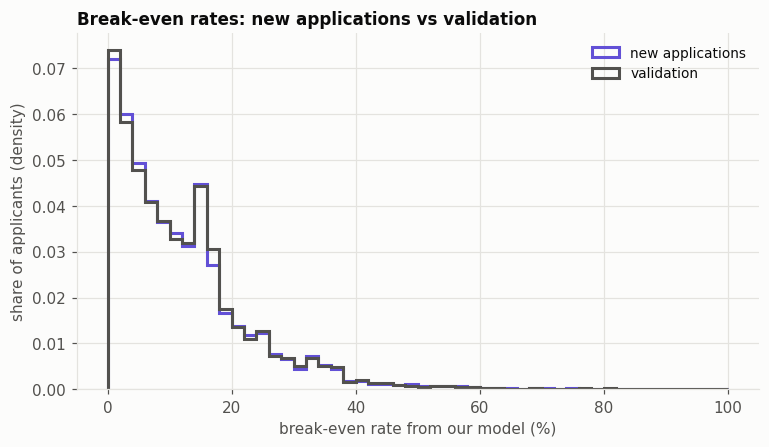

In [8]:
apps_be = add_offer_flags(add_break_even_rates(apps, "p_own"), "p_own")

comparison = pd.DataFrame({
    "applications": apps_be["be_p_own"].describe(percentiles=[0.1, 0.5, 0.9, 0.99]),
    "validation": val_be["be_p_own"].describe(percentiles=[0.1, 0.5, 0.9, 0.99]),
}).drop("count")
display(comparison.style.format("{:.2%}"))
print(f"applicants with no offer (p >= 0.5) : {int((apps_be['offer_p_own'] == 0).sum())}")
print(apps_be.loc[apps_be["offer_p_own"] == 0])

fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.arange(0, 102, 2)
ax.hist(100 * apps_be["be_p_own"].dropna(), bins=bins, density=True, histtype="step", lw=2,
        color=mp.SINGLE_COLOR, label="new applications")
ax.hist(100 * val_be["be_p_own"], bins=bins, density=True, histtype="step", lw=2,
        color=mp.INK_SECONDARY, label="validation")
ax.set_xlabel("break-even rate from our model (%)")
ax.set_ylabel("share of applicants (density)")
ax.set_title("Break-even rates: new applications vs validation")
ax.legend()
plt.show()

### Saving the break-even rates

Saved to `data/predictions/` for Parts 4 to 8:

| file | content |
|---|---|
| `validation_break_even.csv` | `default`, the five `p_*`, their `be_p_*` rates and `offer_p_*` flags |
| `train_oof_break_even.csv` | the same for the 80,000 training loans (out of fold) |
| `applications_break_even.csv` | `p_own`, `be_p_own`, `offer_p_own` for the 100,000 new applicants |

In [9]:
for frame, name in [(val_be, "validation_break_even.csv"), (train_be, "train_oof_break_even.csv"),
                    (apps_be, "applications_break_even.csv")]:
    frame.to_csv(DATA_PREDICTIONS / name)
    print(f"saved data/predictions/{name}: {frame.shape[0]:,} rows, {frame.shape[1]} columns")

saved data/predictions/validation_break_even.csv: 20,000 rows, 16 columns


saved data/predictions/train_oof_break_even.csv: 80,000 rows, 16 columns


saved data/predictions/applications_break_even.csv: 100,000 rows, 3 columns


## 7. Takeaways


1. **Break-even rate** $r^* = p/(1-p)$ is implemented in `break_even_rate`, with no offer (`NaN`) when
   $p \ge 0.5$. It is close to $p$ for safe borrowers and convex for risky ones. Our median break-even
   rate is 9.5%, the mean 12.0%.
2. **The "no offer" rule almost never binds** for our model: no validation borrower and 1 of the
   100,000 new applicants (id 23772, $p = 0.502$).
3. **Break-even pricing breaks even when nothing selects the borrowers**: lending to everyone at our
   break-even rate gives +0.0002 per euro, within noise at every risk level. Our probabilities are
   well calibrated.
4. **Under competition it loses money**: when every lender prices at break-even, the borrowers we win
   default at 10.1% instead of the 8.0% we predicted, and we lose 2.4 cents per euro lent. The
   break-even rate is a **floor, not a price**.
5. **Competitor offers** = their break-even rate + an assumed margin (`competitor_offers`), never
   below 0% and never above 100%. The margin is the scenario parameter of Parts 6 and 7; the larger it
   is, the more of the market we can undercut.
6. **New applications**: break-even rates have the same distribution as on validation (median 9.5%,
   99th percentile 50.8%).

Break-even rates and offer flags for all Part 2 predictions are saved in `data/predictions/`
(`validation_break_even.csv`, `train_oof_break_even.csv`, `applications_break_even.csv`).